In [ ]:
# -*- coding: utf-8 -*-
# ============================================================
# 모델 11개 학습·비교 (GPT-2 AI vs 사람) — 코랩용
# 입력: 피처표_결과.zip 하나만 업로드 (feature_table.csv + text_split.csv)
# 모델
#   베이스라인 2개 (글자 그대로): TF-IDF + 로지스틱 회귀, TF-IDF + 선형 SVM
#   피처 모델 9개 (피처 27개):   결정나무, 로지스틱 회귀, EBM, 랜덤포레스트, Extra Trees,
#                                HistGradientBoosting, LightGBM, XGBoost, CatBoost
# 출력: 모델비교_결과.zip
#   - 모델성능.csv            : 11개 모델의 AUC(95% 신뢰구간)·정확도·F1·AI 탐지율·사람 정확도·학습 시간
#   - test_predictions.csv    : 시험 리뷰별 각 모델의 AI 확률 (오분류 분석·XAI 단계에서 사용)
#   - lightgbm.joblib, ebm.joblib : 해석(XAI) 단계에서 다시 쓸 모델
#   - 그림 M1~M3
# 약 5~8분 소요 (EBM이 가장 오래 걸림)
# ============================================================

# %% 0. 환경 준비와 파일 업로드 ----------------------------------------
import sys, os, re, glob, time, zipfile, subprocess, warnings
from pathlib import Path
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm', 'xgboost', 'catboost', 'interpret'], check=False)
    subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null 2>&1', shell=True, check=False)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve
warnings.filterwarnings('ignore')
try:
    display
except NameError:
    display = print
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)

KFONT = None
for f in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    if os.path.exists(f):
        font_manager.fontManager.addfont(f); plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=f).get_name()
if KFONT is None:
    for p in sorted(glob.glob('/usr/share/fonts/**/*', recursive=True) + glob.glob('C:/Windows/Fonts/*') + glob.glob('/Library/Fonts/*')):
        if re.search(r'(Nanum|NotoSansCJK|NotoSansKR|malgun|AppleSDGothic)', os.path.basename(p), re.I):
            try:
                font_manager.fontManager.addfont(p); plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=p).get_name(); break
            except Exception:
                continue
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 10.5, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E6ECF2', 'axes.axisbelow': True,
                     'text.color': '#3E4C5E', 'axes.labelcolor': '#3E4C5E', 'xtick.color': '#3E4C5E', 'ytick.color': '#3E4C5E',
                     'axes.edgecolor': '#9AA6B2', 'axes.titlecolor': '#3E4C5E'})
# 색상 (EDA와 같은 파스텔 팔레트)
AI_C, AI_E = '#F2ABAE', '#D9798A'          # AI / 강조
HU_C, HU_E = '#8DBDEB', '#4F86B8'          # 사람 / 피처 모델
PERI, PERI_E = '#8F9FE0', '#5E6FBF'        # 베이스라인
NEUTRAL_E, INK, INK2 = '#9AA6B2', '#3E4C5E', '#7A8797'
SEED = 42
N_BOOT = 500
OUT = Path('model_results'); OUT.mkdir(exist_ok=True)

DATA_DIR = Path('/content' if IN_COLAB else '.')
if IN_COLAB:
    from google.colab import files
    files.upload()   # 피처표_결과.zip 선택
for z in DATA_DIR.glob('*.zip'):
    with zipfile.ZipFile(z) as zf:
        for n in zf.namelist():
            if n.endswith(('feature_table.csv', 'text_split.csv', 'feature_info.csv', 'eda_ranking.csv')):
                (DATA_DIR / Path(n).name).write_bytes(zf.read(n))
def find(name):
    hits = sorted(DATA_DIR.glob(f'**/{name}'))
    assert hits, f'{name} 파일이 없어요. 피처표_결과.zip을 업로드하세요.'
    return hits[0]

ft = pd.read_csv(find('feature_table.csv'))
txt = pd.read_csv(find('text_split.csv'))
assert (ft['review_id'].values == txt['review_id'].values).all(), '두 파일의 리뷰 순서가 달라요'
ID_COLS = ['review_id', 'group', 'category', 'split', 'is_ai']
FEATURES = [c for c in ft.columns if c not in ID_COLS]
tr, te = ft['split'] == 'train', ft['split'] == 'test'
X_tr, X_te = ft.loc[tr, FEATURES], ft.loc[te, FEATURES]
y_tr, y_te = ft.loc[tr, 'is_ai'].values, ft.loc[te, 'is_ai'].values
T_tr, T_te = txt.loc[tr, 'text_clean'].fillna(''), txt.loc[te, 'text_clean'].fillna('')
print(f'학습 {tr.sum():,}건 / 시험 {te.sum():,}건 | 피처 {len(FEATURES)}개 | AI 비율 학습 {y_tr.mean():.3f}, 시험 {y_te.mean():.3f}')

Saving 피처표_결과.zip to 피처표_결과.zip
학습 32,171건 / 시험 8,043건 | 피처 27개 | AI 비율 학습 0.499, 시험 0.499


In [ ]:
# %% 1. 모델 정의 --------------------------------------------------------
# 하이퍼파라미터는 기본값 근처로 고정 (튜닝 없이 공정 비교). AI:사람 ≈ 50:50이라 가중치 보정은 하지 않음
BASELINES = {
    'TF-IDF + 로지스틱 회귀': lambda: make_pipeline(TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True),
                                                LogisticRegression(C=4, max_iter=3000)),
    'TF-IDF + 선형 SVM': lambda: make_pipeline(TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True),
                                             LinearSVC(C=0.5)),
}
FEATURE_MODELS = {
    '결정나무(깊이 4)': lambda: DecisionTreeClassifier(max_depth=4, random_state=SEED),
    '로지스틱 회귀': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    '랜덤포레스트': lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    'Extra Trees': lambda: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED),
}
try:
    from lightgbm import LGBMClassifier
    FEATURE_MODELS['LightGBM'] = lambda: LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                                        subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
except ImportError: print('LightGBM 설치 안 됨 → 건너뜀')
try:
    from xgboost import XGBClassifier
    FEATURE_MODELS['XGBoost'] = lambda: XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
                                                      colsample_bytree=0.8, random_state=SEED, n_jobs=-1, eval_metric='logloss')
except ImportError: print('XGBoost 설치 안 됨 → 건너뜀')
try:
    from catboost import CatBoostClassifier
    FEATURE_MODELS['CatBoost'] = lambda: CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0)
except ImportError: print('CatBoost 설치 안 됨 → 건너뜀')
try:
    from interpret.glassbox import ExplainableBoostingClassifier
    FEATURE_MODELS['EBM'] = lambda: ExplainableBoostingClassifier(outer_bags=4, interactions=10, random_state=SEED, n_jobs=-1)
except ImportError: print('interpret(EBM) 설치 안 됨 → 건너뜀')
print('베이스라인:', ', '.join(BASELINES)); print('피처 모델:', ', '.join(FEATURE_MODELS))

def score_of(model, X):
    """AI일 확률(또는 점수). SVM은 확률이 없어서 결정 점수를 씀 (AUC 계산에는 충분)"""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

베이스라인: TF-IDF + 로지스틱 회귀, TF-IDF + 선형 SVM
피처 모델: 결정나무(깊이 4), 로지스틱 회귀, 랜덤포레스트, Extra Trees, HistGradientBoosting, LightGBM, XGBoost, CatBoost, EBM


In [ ]:
# %% 2. 학습과 평가 ------------------------------------------------------
results, preds, fitted = [], {}, {}
def run(name, kind, make, Xtr, Xte):
    t0 = time.time()
    try:
        m = make(); m.fit(Xtr, y_tr)
    except Exception as e:
        print(f'  ✗ {name} 실패: {type(e).__name__}: {e}'); return
    sec = time.time() - t0
    s = score_of(m, Xte)
    yhat = (s >= (0.5 if hasattr(m, 'predict_proba') else 0.0)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, yhat).ravel()
    results.append({'모델': name, '종류': kind, 'AUC': roc_auc_score(y_te, s), '정확도': accuracy_score(y_te, yhat),
                    'F1(AI)': f1_score(y_te, yhat), 'AI 탐지율': tp / (tp + fn), '사람 정확도': tn / (tn + fp),
                    '학습 시간(초)': sec})
    preds[name] = s; fitted[name] = m
    print(f'  ✓ {name:24s} AUC {results[-1]["AUC"]:.3f} | 정확도 {results[-1]["정확도"]:.3f} | {sec:5.1f}초')

print('베이스라인 학습 (1~2분)...')
for n, mk in BASELINES.items(): run(n, '베이스라인 (TF-IDF)', mk, T_tr, T_te)
print('피처 모델 학습 (3~6분)...')
for n, mk in FEATURE_MODELS.items(): run(n, f'피처 모델 ({len(FEATURES)}개)', mk, X_tr, X_te)

베이스라인 학습 (1~2분)...
  ✓ TF-IDF + 로지스틱 회귀         AUC 0.977 | 정확도 0.916 |  13.2초
  ✓ TF-IDF + 선형 SVM          AUC 0.978 | 정확도 0.920 |  13.9초
피처 모델 학습 (3~6분)...
  ✓ 결정나무(깊이 4)               AUC 0.861 | 정확도 0.780 |   0.1초
  ✓ 로지스틱 회귀                  AUC 0.852 | 정확도 0.760 |   0.2초
  ✓ 랜덤포레스트                   AUC 0.917 | 정확도 0.833 |  20.6초
  ✓ Extra Trees              AUC 0.914 | 정확도 0.832 |   8.7초
  ✓ HistGradientBoosting     AUC 0.919 | 정확도 0.834 |   4.6초
  ✓ LightGBM                 AUC 0.924 | 정확도 0.838 |   2.5초
  ✓ XGBoost                  AUC 0.925 | 정확도 0.842 |   4.5초
  ✓ CatBoost                 AUC 0.923 | 정확도 0.839 |   7.6초
  ✓ EBM                      AUC 0.910 | 정확도 0.821 | 145.8초


In [ ]:
# %% 3. 결과표: AUC 95% 신뢰구간 포함 -----------------------------------
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)]
for r in results:
    s = preds[r['모델']]
    b = [roc_auc_score(y_te[i], s[i]) for i in boot_idx]
    r['AUC 하한'], r['AUC 상한'] = np.percentile(b, [2.5, 97.5])
res = pd.DataFrame(results)[['모델', '종류', 'AUC', 'AUC 하한', 'AUC 상한', '정확도', 'F1(AI)', 'AI 탐지율', '사람 정확도', '학습 시간(초)']]
res = res.sort_values('AUC', ascending=False).reset_index(drop=True)
display(res.round(3))

feat_res = res[res['종류'].str.startswith('피처')]
base_best = res[res['종류'].str.startswith('베이스')].iloc[0]
feat_best = feat_res.iloc[0]
print(f"\n최고 베이스라인: {base_best['모델']} AUC {base_best['AUC']:.3f}")
print(f"최고 피처 모델: {feat_best['모델']} AUC {feat_best['AUC']:.3f} → 차이 {base_best['AUC'] - feat_best['AUC']:.3f} (설명 가능성과 맞바꾼 성능)")
XAI_MODEL = 'LightGBM' if 'LightGBM' in preds else feat_best['모델']
print(f'해석(XAI)에 쓸 모델: {XAI_MODEL} (+ EBM은 교차 확인용)')

,모델,종류,AUC,AUC 하한,AUC 상한,정확도,F1(AI),AI 탐지율,사람 정확도,학습 시간(초)
0,TF-IDF + 선형 SVM,베이스라인 (TF-IDF),0.978,0.975,0.980,0.920,0.920,0.919,0.921,13.863
1,TF-IDF + 로지스틱 회귀,베이스라인 (TF-IDF),0.977,0.975,0.979,0.916,0.916,0.913,0.920,13.170
2,XGBoost,피처 모델 (27개),0.925,0.919,0.930,0.842,0.845,0.865,0.819,4.520
3,LightGBM,피처 모델 (27개),0.924,0.918,0.929,0.838,0.841,0.860,0.816,2.549
4,CatBoost,피처 모델 (27개),0.923,0.917,0.928,0.839,0.843,0.866,0.811,7.553
5,HistGradientBoosting,피처 모델 (27개),0.919,0.914,0.925,0.834,0.838,0.864,0.804,4.578
6,랜덤포레스트,피처 모델 (27개),0.917,0.912,0.923,0.833,0.838,0.866,0.800,20.571
7,Extra Trees,피처 모델 (27개),0.914,0.907,0.920,0.832,0.835,0.855,0.809,8.725
8,EBM,피처 모델 (27개),0.910,0.904,0.916,0.821,0.825,0.844,0.799,145.805
9,결정나무(깊이 4),피처 모델 (27개),0.861,0.853,0.868,0.780,0.782,0.792,0.769,0.144



최고 베이스라인: TF-IDF + 선형 SVM AUC 0.978
최고 피처 모델: XGBoost AUC 0.925 → 차이 0.053 (설명 가능성과 맞바꾼 성능)
해석(XAI)에 쓸 모델: LightGBM (+ EBM은 교차 확인용)


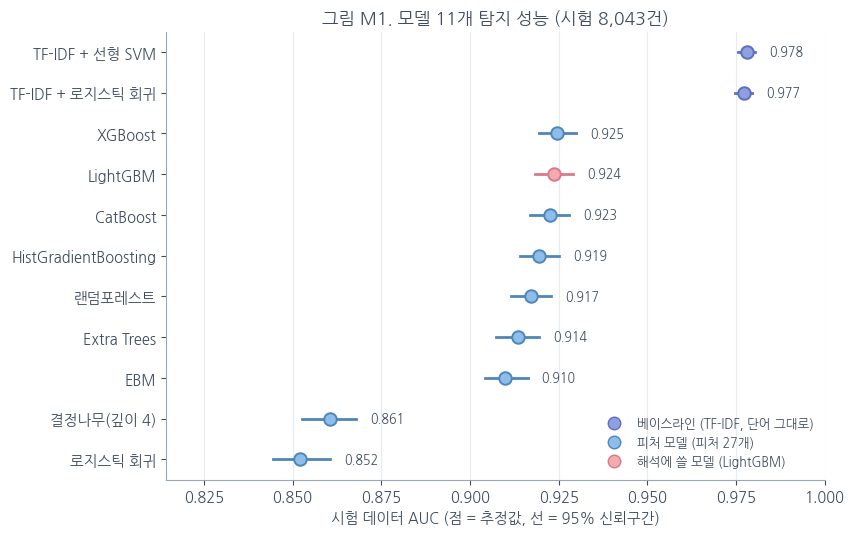

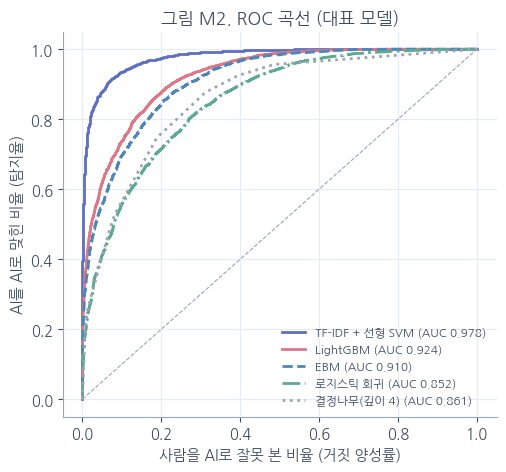

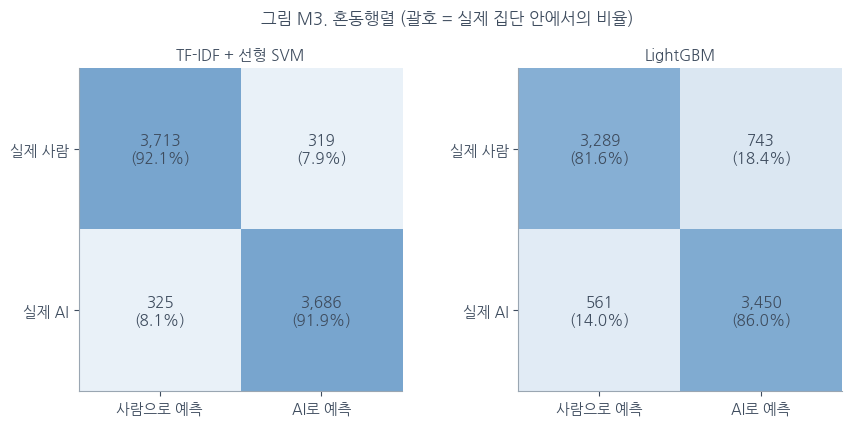

In [ ]:
# %% 4. 그림 --------------------------------------------------------------
# M1. 11개 모델 AUC와 95% 신뢰구간
d = res.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(d) + 1.2))
for i, r in d.iterrows():
    is_base = r['종류'].startswith('베이스'); is_xai = r['모델'] == XAI_MODEL
    fc, ec = (PERI, PERI_E) if is_base else ((AI_C, AI_E) if is_xai else (HU_C, HU_E))
    ax.plot([r['AUC 하한'], r['AUC 상한']], [i, i], color=ec, lw=2)
    ax.plot(r['AUC'], i, 'o', ms=9, mfc=fc, mec=ec, mew=1.4)
    ax.text(r['AUC 상한'] + 0.004, i, f"{r['AUC']:.3f}", va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(d)), d['모델']); ax.grid(axis='y', visible=False)
ax.set_xlim(max(0.5, d['AUC 하한'].min() - 0.03), 1.0); ax.set_xlabel('시험 데이터 AUC (점 = 추정값, 선 = 95% 신뢰구간)')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', mfc=PERI, mec=PERI_E, ms=9, label='베이스라인 (TF-IDF, 단어 그대로)'),
                   Line2D([], [], marker='o', ls='', mfc=HU_C, mec=HU_E, ms=9, label=f'피처 모델 (피처 {len(FEATURES)}개)'),
                   Line2D([], [], marker='o', ls='', mfc=AI_C, mec=AI_E, ms=9, label=f'해석에 쓸 모델 ({XAI_MODEL})')],
          frameon=False, fontsize=9, loc='lower right')
ax.set_title(f'그림 M1. 모델 {len(d)}개 탐지 성능 (시험 {len(y_te):,}건)')
fig.savefig(OUT / 'figM1_AUC비교.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

# M2. ROC 곡선 (대표 모델만)
show = [m for m in [base_best['모델'], XAI_MODEL, 'EBM', '로지스틱 회귀', '결정나무(깊이 4)'] if m in preds]
style = {base_best['모델']: (PERI_E, '-'), XAI_MODEL: (AI_E, '-'), 'EBM': (HU_E, '--'), '로지스틱 회귀': ('#5FA894', '-.'), '결정나무(깊이 4)': (NEUTRAL_E, ':')}
fig, ax = plt.subplots(figsize=(5.6, 5))
for m in dict.fromkeys(show):
    fpr, tpr, _ = roc_curve(y_te, preds[m]); c, ls = style.get(m, (INK2, '-'))
    ax.plot(fpr, tpr, color=c, ls=ls, lw=2, label=f"{m} (AUC {roc_auc_score(y_te, preds[m]):.3f})")
ax.plot([0, 1], [0, 1], color=NEUTRAL_E, lw=0.8, ls='--')
ax.set_xlabel('사람을 AI로 잘못 본 비율 (거짓 양성률)'); ax.set_ylabel('AI를 AI로 맞힌 비율 (탐지율)')
ax.legend(frameon=False, fontsize=8.5, loc='lower right'); ax.set_title('그림 M2. ROC 곡선 (대표 모델)')
fig.savefig(OUT / 'figM2_ROC.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

# M3. 혼동행렬 (최고 베이스라인 vs 해석 모델)
from matplotlib.colors import LinearSegmentedColormap
cm_cmap = LinearSegmentedColormap.from_list('wb', ['#F4F8FC', '#6E9FCB'])
pairs = list(dict.fromkeys([base_best['모델'], XAI_MODEL]))
fig, axs = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 4.2))
axs = np.atleast_1d(axs)
for ax, m in zip(axs, pairs):
    thr = 0.5 if hasattr(fitted[m], 'predict_proba') else 0.0
    cm = confusion_matrix(y_te, (preds[m] >= thr).astype(int)); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap=cm_cmap, vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}\n({cmn[i, j]:.1%})', ha='center', va='center', fontsize=11, color=INK)
    ax.set_xticks([0, 1], ['사람으로 예측', 'AI로 예측']); ax.set_yticks([0, 1], ['실제 사람', '실제 AI'])
    ax.set_title(m, fontsize=11)
fig.suptitle('그림 M3. 혼동행렬 (괄호 = 실제 집단 안에서의 비율)', y=1.02, fontsize=12)
fig.savefig(OUT / 'figM3_혼동행렬.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

In [ ]:
# %% 5. 저장과 다운로드 -------------------------------------------------
res.round(4).to_csv(OUT / '모델성능.csv', index=False, encoding='utf-8-sig')
pred_df = ft.loc[te, ['review_id', 'group', 'category', 'is_ai']].reset_index(drop=True)
for m, s in preds.items(): pred_df[m] = s
pred_df.to_csv(OUT / 'test_predictions.csv', index=False, encoding='utf-8-sig')
for m, fname in [(XAI_MODEL, 'lightgbm.joblib' if XAI_MODEL == 'LightGBM' else 'xai_model.joblib'), ('EBM', 'ebm.joblib')]:
    if m in fitted: joblib.dump(fitted[m], OUT / fname)
for extra in ['feature_info.csv', 'eda_ranking.csv']:   # 다음 단계(XAI)에서 같이 씀
    try: (OUT / extra).write_bytes(find(extra).read_bytes())
    except AssertionError: pass
pd.Series(FEATURES, name='feature').to_csv(OUT / 'feature_order.csv', index=False)

summary = [f'# 모델 비교 핵심 결과', f'- 시험 {len(y_te):,}건 (AI {y_te.sum():,} / 사람 {(1 - y_te).sum():,}), 피처 {len(FEATURES)}개',
           f"- 최고 베이스라인: {base_best['모델']} AUC {base_best['AUC']:.3f} [{base_best['AUC 하한']:.3f}, {base_best['AUC 상한']:.3f}]",
           f"- 최고 피처 모델: {feat_best['모델']} AUC {feat_best['AUC']:.3f} [{feat_best['AUC 하한']:.3f}, {feat_best['AUC 상한']:.3f}]",
           f"- 성능 차이 {base_best['AUC'] - feat_best['AUC']:.3f}: 단어를 그대로 쓰면 더 잘 맞히지만 '왜'를 설명하기 어려움",
           f'- 해석 모델: {XAI_MODEL}'] + \
          [f"- {r['모델']}: AUC {r['AUC']:.3f}, AI 탐지율 {r['AI 탐지율']:.1%}, 사람 정확도 {r['사람 정확도']:.1%}, {r['학습 시간(초)']:.1f}초" for _, r in res.iterrows()]
(OUT / '00_핵심결과_요약.md').write_text('\n'.join(summary), encoding='utf-8'); print('\n'.join(summary))

zip_path = Path('모델비교_결과.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()): z.write(f, arcname=f'model_results/{f.name}')
print('\n저장 완료:', zip_path, f'({zip_path.stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    files.download(str(zip_path))

# 모델 비교 핵심 결과
- 시험 8,043건 (AI 4,011 / 사람 4,032), 피처 27개
- 최고 베이스라인: TF-IDF + 선형 SVM AUC 0.978 [0.975, 0.980]
- 최고 피처 모델: XGBoost AUC 0.925 [0.919, 0.930]
- 성능 차이 0.053: 단어를 그대로 쓰면 더 잘 맞히지만 '왜'를 설명하기 어려움
- 해석 모델: LightGBM
- TF-IDF + 선형 SVM: AUC 0.978, AI 탐지율 91.9%, 사람 정확도 92.1%, 13.9초
- TF-IDF + 로지스틱 회귀: AUC 0.977, AI 탐지율 91.3%, 사람 정확도 92.0%, 13.2초
- XGBoost: AUC 0.925, AI 탐지율 86.5%, 사람 정확도 81.9%, 4.5초
- LightGBM: AUC 0.924, AI 탐지율 86.0%, 사람 정확도 81.6%, 2.5초
- CatBoost: AUC 0.923, AI 탐지율 86.6%, 사람 정확도 81.1%, 7.6초
- HistGradientBoosting: AUC 0.919, AI 탐지율 86.4%, 사람 정확도 80.4%, 4.6초
- 랜덤포레스트: AUC 0.917, AI 탐지율 86.6%, 사람 정확도 80.0%, 20.6초
- Extra Trees: AUC 0.914, AI 탐지율 85.5%, 사람 정확도 80.9%, 8.7초
- EBM: AUC 0.910, AI 탐지율 84.4%, 사람 정확도 79.9%, 145.8초
- 결정나무(깊이 4): AUC 0.861, AI 탐지율 79.2%, 사람 정확도 76.9%, 0.1초
- 로지스틱 회귀: AUC 0.852, AI 탐지율 75.1%, 사람 정확도 76.9%, 0.2초

저장 완료: 모델비교_결과.zip (3.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

원래 메인모델 lightGBM+EBM  사용하여 shap

-> but auc나 탐지율 등에서 xgb가 우세
->시간 소요량도 고려사항에 포함?
그러면lightgbm인데...